# LoTUS-BF 改進版：Validation Report 與 AI 協作心得

| 項目 | 內容 |
|---|---|
| 姓名 / 學號 | （請填寫） |
| 網站 URL | `http://hpc.psy.ntu.edu.tw:3010/lotus-bf/` （port 3000 為課程範例網站，故本作業部署於 3010；此伺服器的網頁僅限校內網路／NTU VPN 存取） |
| 程式包 | `lotus-bf-improved.zip`（已移除 `node_modules`） |
| 報告日期 | 2026-11-11 |

**LoTUS-BF**（Location-or-Term Unified Search for Brain Functions）讓使用者以「詞彙」與「MNI 座標」混合的布林查詢搜尋 Neurosynth 研究，並產生 meta-analytic 腦圖。

本報告分成三部分：
1. **問題發現**：在原始版本中重現的錯誤（含證據）
2. **驗證**：以「已知答案」的測試資料庫，逐項比較原始版與改進版的輸出；並驗證前端行為、NIfTI 腦圖與錯誤處理
3. **AI 協作心得**

## 0. 驗證環境與方法

課程資料庫的帳密不在程式碼中，而且真實資料沒有「標準答案」可以比對，因此主要驗證使用一個**結構與課程資料庫相同的合成資料庫**（`tests/seed_db.py`）：

* schema `ns`：`metadata`（含 `fts` tsvector）、`coordinates`（PostGIS PointZ）、`annotations_json`（`terms_abstract_tfidf__*` 鍵）
* 8 篇**人工設計**的研究（標題、座標、詞彙都已知 → 正確答案可事先寫出）＋ 300 篇隨機填充研究（不含核心詞彙，座標隨機）
* 布林查詢的正確答案用 **「集合運算 oracle」** 產生：先驗證單一詞彙／單一座標的結果（詞彙對照人工答案、座標用 Python 自行計算歐氏距離），再用 Python 的 `|`、`&`、`-` 組合成複合查詢的期望結果，與後端 SQL 的輸出比對。

最後一節另有**連線到正式網站的檢查**（部署後執行）。

> 重新執行本 notebook：設定 `LOTUS_DIR`（專案資料夾）與 `DB_URL`（測試資料庫，先執行 `python tests/seed_db.py "<dsn>"`）。

In [1]:
import os, sys, json, time, math, subprocess, importlib.util, pathlib, gzip, io
import pandas as pd
pd.set_option("display.max_colwidth", 80)

LOTUS_DIR = pathlib.Path(os.environ.get("LOTUS_DIR", "lotus-bf")).resolve()
DB_URL    = os.environ.get("DB_URL")            # synthetic test DB
LIVE_URL  = os.environ.get("LIVE_URL", "http://hpc.psy.ntu.edu.tw:3010/lotus-bf/")
assert (LOTUS_DIR / "app.py").exists(), f"app.py not found in {LOTUS_DIR}"
print("project :", LOTUS_DIR)
print("test DB :", "set" if DB_URL else "NOT SET")

def load(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec); sys.modules[name] = mod; spec.loader.exec_module(mod)
    return mod

new = load("lotus_new", LOTUS_DIR / "app.py")                          # improved backend
old = load("lotus_old", LOTUS_DIR / "tests/legacy/app_original.py")    # original backend (unchanged logic)
app_old = old.create_app()
app_old.logger.disabled = True       # the original backend prints full tracebacks for its 500 errors
cn, co = new.create_app().test_client(), app_old.test_client()

from sqlalchemy import text
with new.get_engine().connect() as c:
    n_studies = c.execute(text("select count(*) from ns.metadata")).scalar()
    n_coords  = c.execute(text("select count(*) from ns.coordinates")).scalar()
    coords = c.execute(text("select study_id, ST_X(geom), ST_Y(geom), ST_Z(geom) from ns.coordinates")).all()
    UNIVERSE = {r[0] for r in c.execute(text("select study_id from ns.metadata"))}
print(f"synthetic DB: {n_studies} studies, {n_coords} coordinates")

project : /home/claude/src/lotus-bf
test DB : set


synthetic DB: 308 studies, 1027 coordinates


## 1. 在原始版本中發現的問題

| # | 位置 | 問題 | 影響 |
|---|---|---|---|
| B1 | 後端 `_split_mixed_query` | 第一個 `OR` 被丟棄並當成 AND | `pain OR emotion` 只回傳同時含兩者的研究 |
| B2 | 後端 `_split_mixed_query` | 詞彙外的括號被移除 | `(pain OR emotion) AND memory` 的優先順序錯誤 |
| B3 | 後端 | 詞彙與座標分開計算後一律取交集（INTERSECT） | `[x,y,z] OR memory` 實際上變成 AND |
| B4 | 後端 `_normalize_query` | 正規表示式把以 and/or/not 開頭的單字拆開：`orbitofrontal` → `or bitofrontal` | `orbitofrontal`、`orientation`、`notion`… 查詢 → **HTTP 500** |
| B5 | 後端 | 語法錯誤、tsquery 錯誤沒有被捕捉 | 回傳 HTML 500 頁面，前端只能顯示 “HTTP 500” |
| B6 | 後端 | 資料庫帳密寫死在原始碼；沒有 `app` 物件／啟動入口；`kernel=uniform`、`voxel` 參數無作用；`r` 無上下限 | 安全性與可部署性 |
| F1 | 前端 | 每打一個字就送出 studies **與** NIfTI 產生請求（NIfTI 請求不會中止） | 輸入 `pain OR emotion` 共送出 30 個請求，後端負擔大且結果閃爍 |
| F2 | 前端 | 使用 Tailwind class，但專案**沒有安裝 Tailwind**；Vite 範本 `index.css` 設定 `body{display:flex}` 與深色主題 | 腦切片只有約 90px、表格無樣式、右欄溢出 |
| F3 | 前端 | `ErrorBoundary` 以字串傳給 `style`，本身就會丟出錯誤 | 任何執行期錯誤 → 空白頁 |
| F4 | 前端 | 點選多字詞（如 *default mode*）未加引號 | 被拆成 `default AND mode` |
| F5 | 前端 | `/terms/<term>`（相關詞）與 `Locations` 元件寫好卻沒有使用；無法設定半徑 r | 功能未發揮 |
| F6 | 前端 | 背景模板使用相對路徑 `static/...`，網址少了結尾 `/` 時會載入失敗 | 部署脆弱 |

以下以實際查詢重現 B1–B5。

In [2]:
def ids(client, q, **params):
    r = client.get(f"/query/{q}/studies", query_string=params)
    if r.status_code != 200:
        return f"HTTP {r.status_code}"
    return sorted(x["study_id"] for x in r.get_json()["results"])

def near(p, r=6.0):
    return {sid for sid, x, y, z in coords if math.dist((x, y, z), p) < r}

# ---- Step 1: validate single operands against independent ground truth
TRUTH = {  # from the hand-built studies in tests/seed_db.py
    "emotion": {"90000002", "90000004", "90000008"}, "pain": {"90000004", "90000006"},
    "memory": {"90000003", "90000006"}, "reward": {"90000001", "90000008"},
    "orbitofrontal": {"90000001"}, "orientation": {"90000007"}, '"default mode"': {"90000005"},
}
rows = []
for q, truth in TRUTH.items():
    rows.append({"query": q, "expected": sorted(truth), "original": ids(co, q), "improved": ids(cn, q)})
for p in [(-22, -4, -18), (-2, 50, -6), (0, -52, 26)]:
    q = "[" + ",".join(map(str, p)) + "]"
    rows.append({"query": q, "expected": sorted(near(p)), "original": ids(co, q), "improved": ids(cn, q)})
df1 = pd.DataFrame(rows)
df1["original OK"] = df1.apply(lambda r: r.original == r.expected, axis=1)
df1["improved OK"] = df1.apply(lambda r: r.improved == r.expected, axis=1)
df1

,query,expected,original,improved,original OK,improved OK
0,emotion,"[90000002, 90000004, 90000008]","[90000002, 90000004, 90000008]","[90000002, 90000004, 90000008]",True,True
1,pain,"[90000004, 90000006]","[90000004, 90000006]","[90000004, 90000006]",True,True
2,memory,"[90000003, 90000006]","[90000003, 90000006]","[90000003, 90000006]",True,True
3,reward,"[90000001, 90000008]","[90000001, 90000008]","[90000001, 90000008]",True,True
4,orbitofrontal,[90000001],HTTP 500,[90000001],False,True
5,orientation,[90000007],HTTP 500,[90000007],False,True
6,"""default mode""",[90000005],[90000005],[90000005],True,True
7,"[-22,-4,-18]","[90000002, 90000004]","[90000002, 90000004]","[90000002, 90000004]",True,True
8,"[-2,50,-6]","[90000001, 90000008]","[90000001, 90000008]","[90000001, 90000008]",True,True
9,"[0,-52,26]","[80000195, 90000005, 90000006]","[80000195, 90000005, 90000006]","[80000195, 90000005, 90000006]",True,True


單一運算元時，原始版只在 `orbitofrontal`、`orientation` 失敗（B4，HTTP 500），其餘正確。因此以下把**經過驗證的單一結果**當作基礎，用 Python 集合運算產生複合查詢的期望答案。

In [3]:
S = {k.strip('"'): set(v) for k, v in TRUTH.items()}
E, P, M, R = S["emotion"], S["pain"], S["memory"], S["reward"]
A = near((-22, -4, -18)); O = near((-2, 50, -6))
CASES = {
    "pain OR emotion":                          P | E,
    "(pain OR emotion) AND memory":             (P | E) & M,
    "pain OR emotion AND memory":               P | (E & M),
    "reward NOT emotion":                       R - E,
    "NOT emotion":                              UNIVERSE - E,
    "[-22,-4,-18] AND emotion":                 A & E,
    "[-22,-4,-18] NOT pain":                    A - P,
    "[-22,-4,-18] OR memory":                   A | M,
    "[-2,50,-6] OR [-22,-4,-18]":               O | A,
    "([-22,-4,-18] OR reward) AND NOT pain":    (A | R) - P,
    "orbitofrontal OR orientation":             S["orbitofrontal"] | S["orientation"],
}
rows = []
for q, exp in CASES.items():
    o, n = ids(co, q), ids(cn, q)
    short = lambda v: v if isinstance(v, str) else (f"{len(v)} studies" if len(v) > 6 else v)
    rows.append({"query": q, "expected": short(sorted(exp)), "original": short(o), "improved": short(n),
                 "original OK": o == sorted(exp), "improved OK": n == sorted(exp)})
df2 = pd.DataFrame(rows)
display(df2)
print(f"original: {df2['original OK'].sum()}/{len(df2)} correct   improved: {df2['improved OK'].sum()}/{len(df2)} correct")

,query,expected,original,improved,original OK,improved OK
0,pain OR emotion,"[90000002, 90000004, 90000006, 90000008]",[90000004],"[90000002, 90000004, 90000006, 90000008]",False,True
1,(pain OR emotion) AND memory,[90000006],[],[90000006],False,True
2,pain OR emotion AND memory,"[90000004, 90000006]",[],"[90000004, 90000006]",False,True
3,reward NOT emotion,[90000001],[90000001],[90000001],True,True
4,NOT emotion,305 studies,305 studies,305 studies,True,True
5,"[-22,-4,-18] AND emotion","[90000002, 90000004]","[90000002, 90000004]","[90000002, 90000004]",True,True
6,"[-22,-4,-18] NOT pain",[90000002],[90000002],[90000002],True,True
7,"[-22,-4,-18] OR memory","[90000002, 90000003, 90000004, 90000006]",[],"[90000002, 90000003, 90000004, 90000006]",False,True
8,"[-2,50,-6] OR [-22,-4,-18]","[90000001, 90000002, 90000004, 90000008]","[90000001, 90000002, 90000004, 90000008]","[90000001, 90000002, 90000004, 90000008]",True,True
9,"([-22,-4,-18] OR reward) AND NOT pain","[90000001, 90000002, 90000008]",[],"[90000001, 90000002, 90000008]",False,True


original: 5/11 correct   improved: 11/11 correct


### 1.1 查詢如何被解讀
新增的 `GET /query/<q>/parse` 端點（不存取資料庫）回傳加上完整括號的解讀結果；前端在使用者輸入時即時顯示，讓布林優先順序（NOT > AND > OR）一目了然。原始版的對應結果則取自其 `_split_mixed_query`。

In [4]:
rows = []
for q in ["pain OR emotion", "(pain OR emotion) AND memory", "[-22,-4,-18] OR memory",
          "reward NOT emotion", "orbitofrontal", '"default mode" [0,-52,26]']:
    try:
        t, l = old._split_mixed_query(q); orig = f"terms={t!r}  locations={l!r}  (combined with INTERSECT)"
    except Exception as e:
        orig = f"error: {e}"
    try:
        orig_ts = old._build_full_tsquery(t) if t else ""
    except Exception as e:
        orig_ts = f"error: {e}"
    rows.append({"query": q, "original split": orig, "original tsquery": orig_ts,
                 "improved (/parse)": cn.get(f"/query/{q}/parse").get_json().get("interpreted")})
pd.DataFrame(rows)

,query,original split,original tsquery,improved (/parse)
0,pain OR emotion,terms='pain emotion' locations=None (combined with INTERSECT),(pain) & (emotion),(pain OR emotion)
1,(pain OR emotion) AND memory,terms='pain emotion AND memory' locations=None (combined with INTERSECT),((pain) & (emotion)) & (memory),((pain OR emotion) AND memory)
2,"[-22,-4,-18] OR memory","terms='memory' locations='[-22,-4,-18]' (combined with INTERSECT)",memory,"([-22,-4,-18] OR memory)"
3,reward NOT emotion,terms='reward NOT emotion' locations=None (combined with INTERSECT),(reward) & (!(emotion)),(reward AND NOT emotion)
4,orbitofrontal,terms='orbitofrontal' locations=None (combined with INTERSECT),error: Unexpected token: OR,orbitofrontal
5,"""default mode"" [0,-52,26]","terms='""default mode""' locations='[0,-52,26]' (combined with INTERSECT)",(default <-> mode),"(""default mode"" AND [0,-52,26])"


## 2. 錯誤處理（B5）
不合法的查詢應回傳 **HTTP 400 + JSON 錯誤訊息**，前端才能直接顯示原因。

In [5]:
rows = []
for q in ["emotion AND", "(pain", "pain)", "[1,2]", "[1,2,3", "&&&", "orientation"]:
    ro, rn = co.get(f"/query/{q}/studies"), cn.get(f"/query/{q}/studies")
    rows.append({"query": q, "original status": ro.status_code,
                 "original body": (ro.get_json() or {}).get("error") if ro.is_json else ro.data[:40].decode(errors="ignore") + "…",
                 "improved status": rn.status_code,
                 "improved message": (rn.get_json() or {}).get("error", "(ok)") if rn.status_code != 200 else f"OK, {rn.get_json()['count']} result(s)"})
pd.DataFrame(rows)

,query,original status,original body,improved status,improved message
0,emotion AND,200,NaN,400,Query is incomplete: a term or location is expected at the end.
1,(pain,200,NaN,400,Missing ')' for '(' at position 0.
2,pain),200,NaN,400,Unmatched ')' at position 4.
3,"[1,2]",500,<!doctype html>\n<html lang=en>\n<title>50…,400,"Invalid coordinate [1,2]. Use three numbers, e.g. [-22,-4,18]."
4,"[1,2,3",200,NaN,400,"Unclosed '[' at position 0. Locations look like [x,y,z]."
5,&&&,500,<!doctype html>\n<html lang=en>\n<title>50…,400,Term '&&&' has no searchable letters or digits.
6,orientation,500,<!doctype html>\n<html lang=en>\n<title>50…,200,"OK, 1 result(s)"


## 3. 自動化測試（pytest）
`tests/test_api.py` 共 39 項：parser 單元測試（不需資料庫）＋ API 整合測試（boolean oracle、HW08 資料表結構相容、半徑 3/6/12 mm 的歐氏距離比對、錯誤碼、NIfTI、terms）。

In [6]:
res = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "--color=no", str(LOTUS_DIR / "tests")],
                     capture_output=True, text=True, env={**os.environ, "DB_URL": DB_URL or ""})
print(res.stdout[-1500:] or res.stderr[-1500:])

.......................................                                  [100%]
39 passed in 1.08s



## 4. NIfTI 腦圖驗證
檢查項目：(a) 維度與 affine 與前端背景模板 `mni_2mm.nii.gz` 一致；(b) `fwhm=0` 時體素總和 = 座標數；(c) 高斯平滑後的數值單位：單一孤立 focus 的峰值 = 1（改進後的定義，數值可讀作「附近有幾個 foci」）；(d) 峰值位置落在正確的 MNI 座標。

In [7]:
import nibabel as nib, numpy as np
bg = nib.load(LOTUS_DIR / "public/static/mni_2mm.nii.gz")
def get_map(q, **p):
    r = cn.get(f"/query/{q}/nii", query_string=p)
    return nib.Nifti1Image.from_bytes(gzip.decompress(r.data)), r.headers
img0, h0 = get_map("emotion", fwhm=0)
img,  h  = get_map("emotion", fwhm=10)
locs = cn.get("/query/emotion/locations").get_json()
d = img.get_fdata()
peak_vox = np.unravel_index(d.argmax(), d.shape)
peak_mni = (img.affine @ [*peak_vox, 1])[:3]
single, _ = get_map('"default mode"', fwhm=10)        # one study, one focus
checks = {
    "shape == template":                img.shape == bg.shape,
    "affine == template":               bool(np.allclose(img.affine, bg.affine)),
    "fwhm=0: sum == #locations":        int(img0.get_fdata().sum()) == locs["location_counts"],
    "single focus peak == 1.0":         round(float(single.get_fdata().max()), 3) == 1.0,
    "emotion peak at [-22,-4,-18]":     list(map(int, peak_mni)) == [-22, -4, -18],
    "emotion peak value ≈ 2 (2 studies)": round(float(d.max()), 2) == 2.0,
    "X-LoTUS-Studies header":           h["X-LoTUS-Studies"] == "3",
}
pd.Series(checks, name="pass")

shape == template                     True
affine == template                    True
fwhm=0: sum == #locations             True
single focus peak == 1.0              True
emotion peak at [-22,-4,-18]          True
emotion peak value ≈ 2 (2 studies)    True
X-LoTUS-Studies header                True
Name: pass, dtype: bool

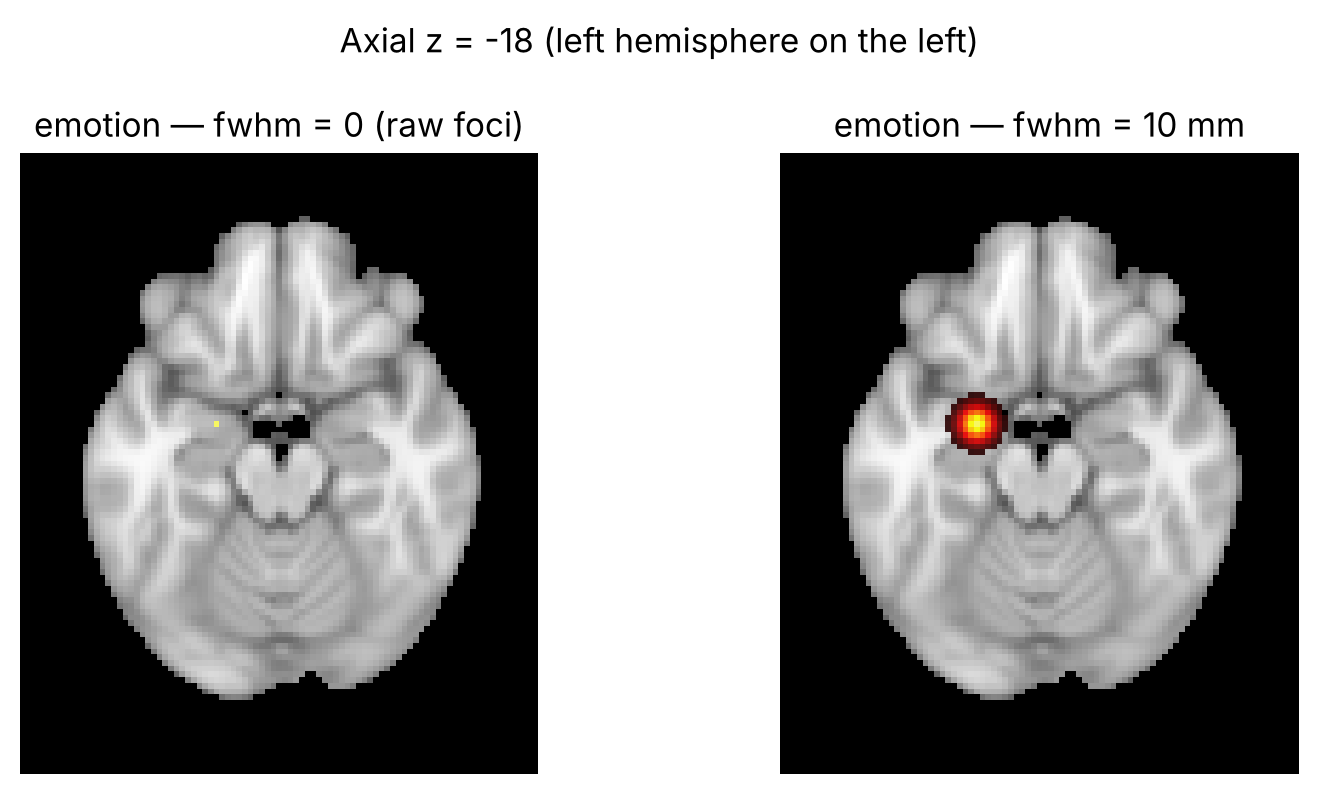

In [8]:
import matplotlib.pyplot as plt
k = int(round((-18 + 72) / 2))           # axial slice z = -18
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for a, (m, title) in zip(ax, [(img0, "fwhm = 0 (raw foci)"), (img, "fwhm = 10 mm")]):
    a.imshow(np.rot90(bg.get_fdata()[::-1, :, k]), cmap="gray")
    ov = np.rot90(m.get_fdata()[::-1, :, k]); ov = np.ma.masked_where(ov <= 0.05 * ov.max(), ov)
    a.imshow(ov, cmap="hot", alpha=.9, vmin=0, vmax=ov.max() * 1.2); a.set_title(f"emotion — {title}"); a.axis("off")
plt.suptitle("Axial z = -18 (left hemisphere on the left)"); plt.tight_layout(); plt.show()

## 5. 前端驗證

### 5.1 Build 與 Lint

In [9]:
if (LOTUS_DIR / "node_modules").exists():
    for cmd in (["npx", "eslint", "src"], ["npm", "run", "build"]):
        r = subprocess.run(cmd, cwd=LOTUS_DIR, capture_output=True, text=True)
        print("$", " ".join(cmd), "→ exit", r.returncode); print((r.stdout + r.stderr).strip()[-600:] or "(no warnings)"); print()
else:
    print("node_modules not installed — run `npm install` first (skipped)")

$ npx eslint src → exit 0
(no warnings)



$ npm run build → exit 0
> lotus-frontend@0.0.0 build
> vite build

vite v7.3.7 building client environment for production...
transforming...
✓ 45 modules transformed.
rendering chunks...
computing gzip size...
dist/index.html                   0.53 kB │ gzip:  0.39 kB
dist/assets/index-BrzXrTQg.css    9.02 kB │ gzip:  2.73 kB
dist/assets/index-Dv5eTlww.js   281.27 kB │ gzip: 87.69 kB
✓ built in 1.36s



### 5.2 瀏覽器端功能測試（Playwright）
`tests/ui_check.py` 以 headless Chromium 操作網站（後端連到合成資料庫），結果存於 `docs/ui_results.json`。原始版的請求數用同樣方式量測（輸入 `pain OR emotion`）。

In [10]:
ui = json.loads((LOTUS_DIR / "docs/ui_results.json").read_text())
before_requests = {"studies": 15, "nii": 15}   # measured on the original frontend while typing "pain OR emotion"
checks = [
    ("輸入時不再觸發 studies / nii 查詢", f"original: {sum(before_requests.values())} requests", f"improved: {ui['calls_while_typing']} only", ui["calls_while_typing"] == ["parse"]),
    ("即時顯示查詢解讀", "—", ui["interpreted_preview"], "((pain OR emotion) AND memory)" in ui["interpreted_preview"]),
    ("布林查詢結果正確", "0 studies", f"{ui['studies_bar']}: {ui['study_titles']}", ui["study_titles"] == ["Memory retrieval and pain"]),
    ("語法錯誤即時提示", "HTTP 500", ui["syntax_error_preview"], "incomplete" in ui["syntax_error_preview"]),
    ("多字詞自動加引號＋可選 OR", "default mode (未加引號)", ui["query_after_term_clicks"], ui["query_after_term_clicks"] == '"default mode" OR orbitofrontal'),
    ("相關詞（/terms/<term>）", "未使用", ", ".join(t.split("\n")[0] for t in ui["related_terms"]), len(ui["related_terms"]) > 0),
    ("座標 OR 詞彙", "0 studies", ui["loc_or_term_studies"], ui["loc_or_term_studies"].startswith("4")),
    ("點 Locations 表格列 → 移動腦圖游標", "無此功能", str(ui["cursor_after_row_click"]), ui["cursor_after_row_click"] == ["-22", "-4", "-18"]),
    ("點擊腦切片的座標換算", "—", str(ui["axial_click_xyz"]), ui["axial_click_xyz"][:2] == ["40", "30"]),
    ("把游標座標加入查詢（保留優先順序）", "無此功能", ui["query_after_add_location"], ui["query_after_add_location"].startswith("(")),
    ("分享網址可還原查詢", "—", str(ui["shared_url_titles"]), ui["shared_url_titles"] == ["Orbitofrontal cortex encodes reward value"]),
    ("瀏覽器 JS 錯誤", "—", str(ui["page_errors"]), ui["page_errors"] == []),
]
pd.DataFrame(checks, columns=["check", "original", "improved", "pass"])

,check,original,improved,pass
0,輸入時不再觸發 studies / nii 查詢,original: 30 requests,improved: ['parse'] only,True
1,即時顯示查詢解讀,—,Interpreted as ((pain OR emotion) AND memory)press Enter to search,True
2,布林查詢結果正確,0 studies,1 study: ['Memory retrieval and pain'],True
3,語法錯誤即時提示,HTTP 500,⚠ Query is incomplete: a term or location is expected at the end.,True
4,多字詞自動加引號＋可選 OR,default mode (未加引號),"""default mode"" OR orbitofrontal",True
5,相關詞（/terms/<term>）,未使用,"amygdala, faces, pain, reward",True
6,座標 OR 詞彙,0 studies,4 studies,True
7,點 Locations 表格列 → 移動腦圖游標,無此功能,"['-22', '-4', '-18']",True
8,點擊腦切片的座標換算,—,"['40', '30', '-18']",True
9,把游標座標加入查詢（保留優先順序）,無此功能,"([-22,-4,-18] OR memory) [-22,-4,-18]",True


### 5.3 畫面比較（Before / After）

**Before**：腦切片僅約 90px、右欄溢出、`pain OR emotion` 只有 1 筆

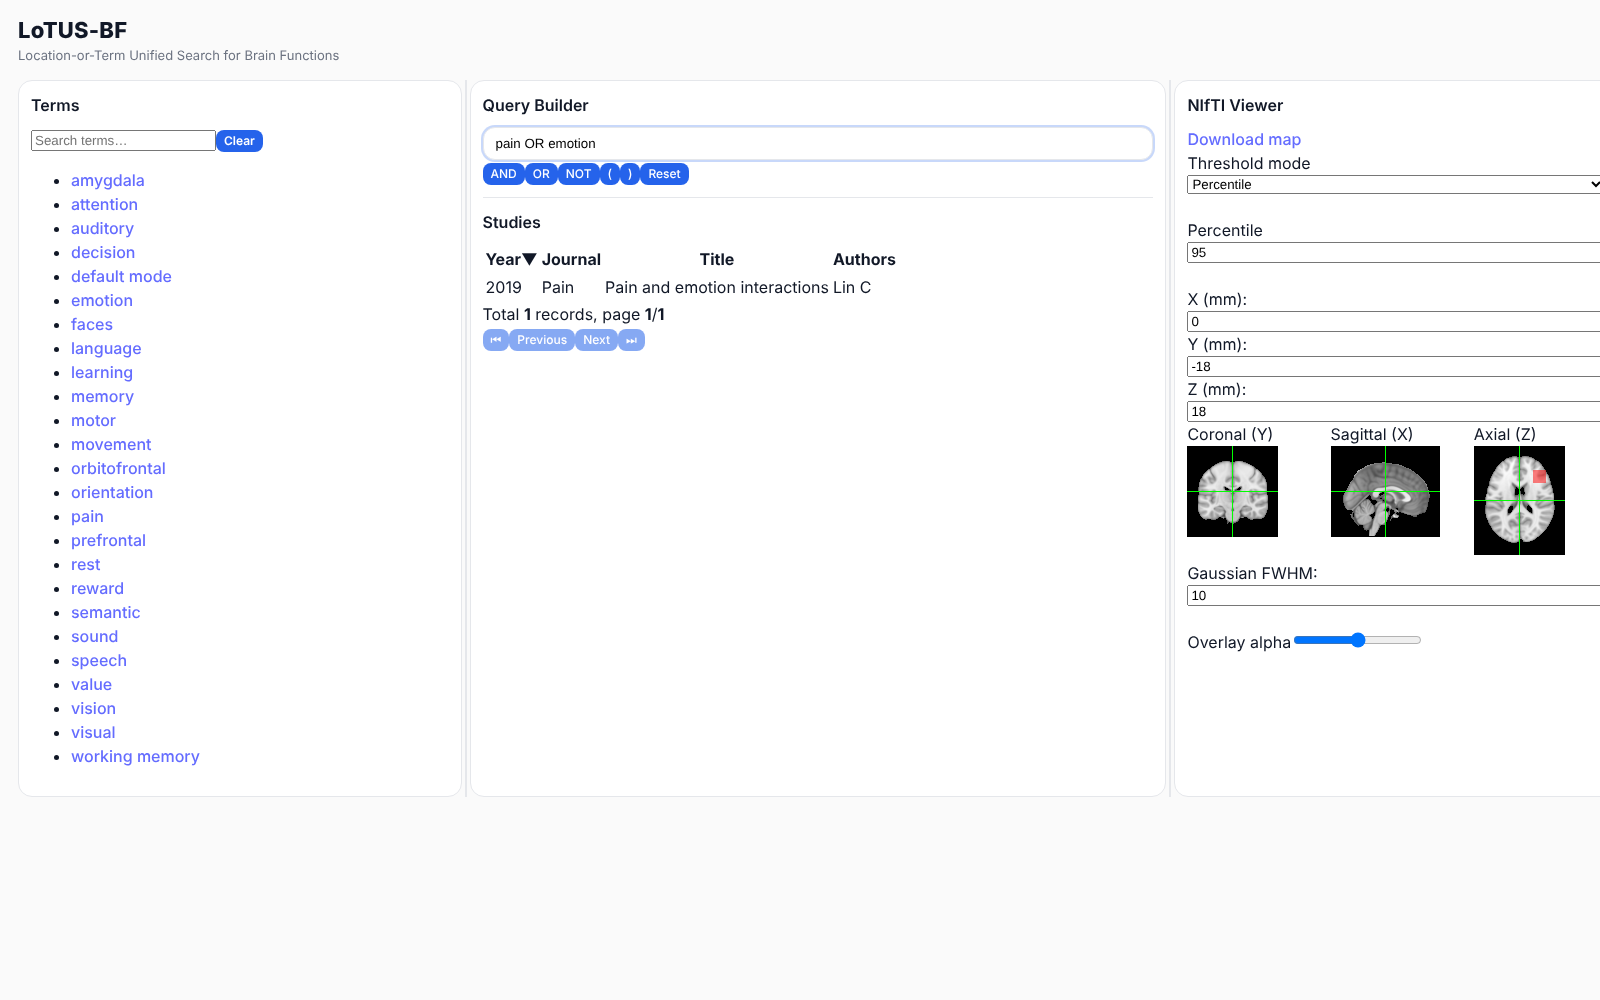

**After**：`(pain OR emotion) AND memory` 正確，顯示查詢解讀

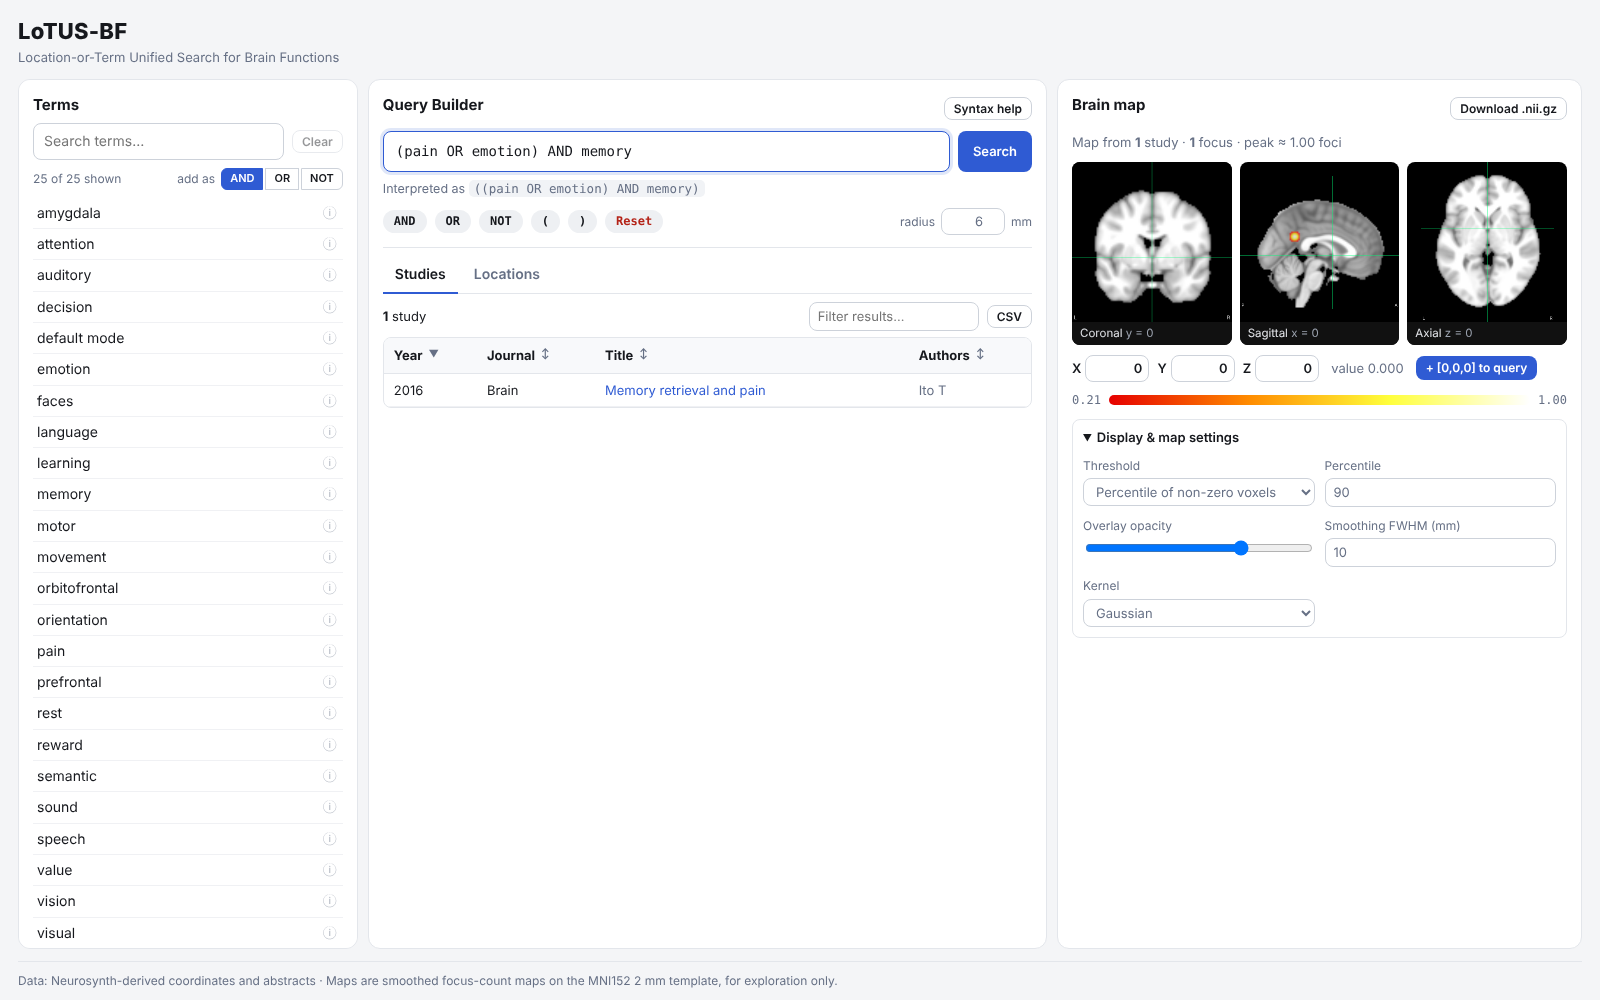

**After**：座標 OR 詞彙、Locations 分頁、相關詞、hot colormap 與 colorbar

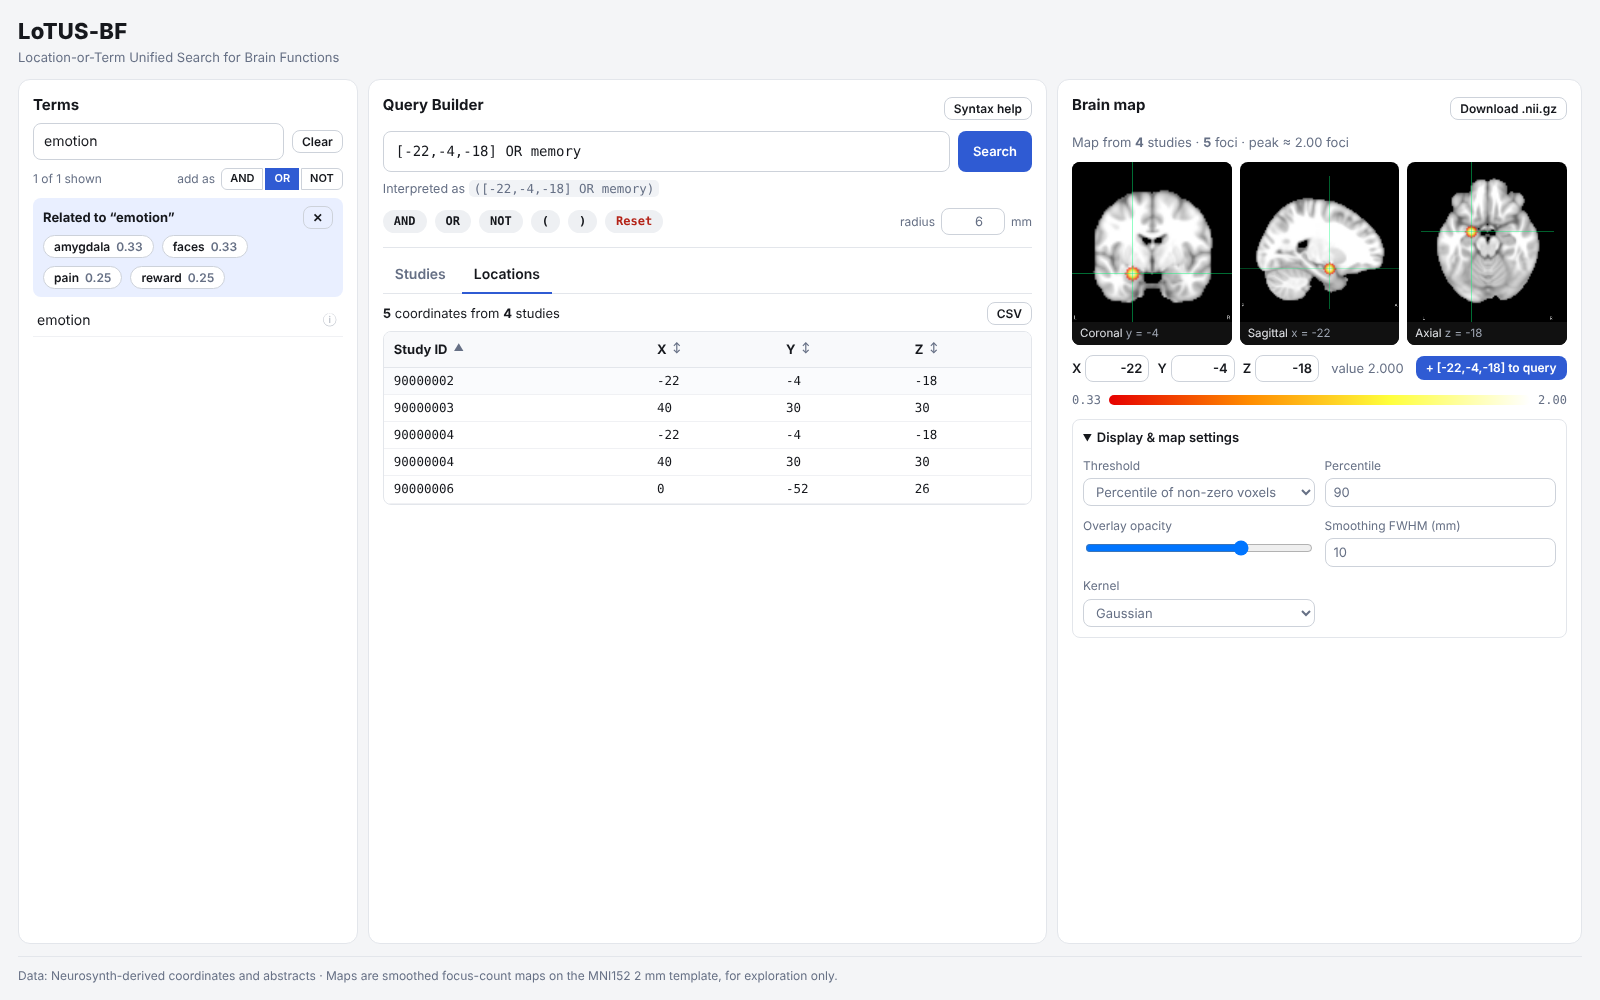

**After**：語法錯誤即時提示

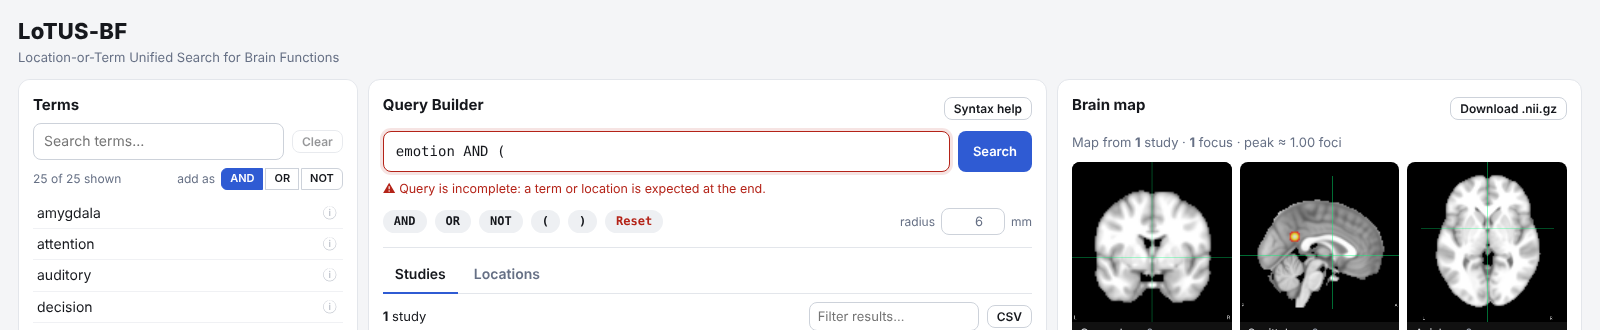

In [11]:
from IPython.display import Image, display, Markdown
for f, cap in [("00_before.png", "**Before**：腦切片僅約 90px、右欄溢出、`pain OR emotion` 只有 1 筆"),
               ("02_boolean_query.png", "**After**：`(pain OR emotion) AND memory` 正確，顯示查詢解讀"),
               ("04_location_or_term.png", "**After**：座標 OR 詞彙、Locations 分頁、相關詞、hot colormap 與 colorbar"),
               ("03_syntax_error.png", "**After**：語法錯誤即時提示")]:
    p = LOTUS_DIR / "docs/screenshots" / f
    if p.exists():
        display(Markdown(cap)); display(Image(filename=str(p), width=900))

## 6. 效能（合成資料庫上的回應時間）
改進版把詞彙與座標合併成**單一 SQL WHERE**，座標比對仍沿用原本「先算 hits CTE 再 EXISTS」的做法，因此效能不應退步。另外前端改成按 Enter 才查詢，請求數從每個字元 2 個降為每次搜尋 3 個（studies、nii、及切換分頁時的 locations）。

In [12]:
def timeit(client, q, n=5):
    t = time.perf_counter()
    for _ in range(n): client.get(f"/query/{q}/studies")
    return (time.perf_counter() - t) / n * 1000
rows = [{"query": q, "original ms": round(timeit(co, q), 1), "improved ms": round(timeit(cn, q), 1)}
        for q in ["emotion", "[-22,-4,-18]", "[-22,-4,-18] AND emotion", "reward NOT emotion"]]
pd.DataFrame(rows)

,query,original ms,improved ms
0,emotion,3.3,2.2
1,"[-22,-4,-18]",2.3,1.5
2,"[-22,-4,-18] AND emotion",3.0,2.9
3,reward NOT emotion,3.4,2.7


## 7. 正式網站檢查
網站已部署於 `http://hpc.psy.ntu.edu.tw:3010/lotus-bf/`（後端 port 5010；port 3000 為課程範例網站所用）。部署當下已在伺服器本機驗證：`curl http://localhost:3010/lotus-bf/` 回傳 200，後端連上 Render PostgreSQL 資料庫（3168 個詞彙）。

此伺服器的網頁連接埠僅限校內網路存取，以下 cell 需在校內網路或 NTU VPN 環境下執行才會通過；在連不到伺服器的環境會顯示 *skipped*。

In [13]:
import requests
from urllib.parse import urljoin, quote
origin = LIVE_URL.split("/lotus-bf")[0]
live_checks = [
    ("frontend page",            LIVE_URL,                                              lambda r: "LoTUS" in r.text or "root" in r.text),
    ("background template",      urljoin(LIVE_URL, "static/mni_2mm.nii.gz"),            lambda r: len(r.content) > 100000),
    ("GET /terms",               origin + "/terms",                                     lambda r: len(r.json()["terms"]) > 100),
    ("GET /query/…/parse (new)", origin + "/query/" + quote("(pain OR emotion) AND memory") + "/parse", lambda r: r.json()["interpreted"] == "((pain OR emotion) AND memory)"),
    ("orbitofrontal no longer 500", origin + "/query/orbitofrontal/studies",            lambda r: r.json()["count"] > 0),
    ("OR is a union",            origin + "/query/" + quote("pain OR emotion") + "/studies", lambda r: r.json()["count"] >= requests.get(origin + "/query/emotion/studies", timeout=60).json()["count"]),
    ("syntax error → 400 JSON",  origin + "/query/" + quote("emotion AND") + "/studies", lambda r: r.status_code == 400 and "error" in r.json()),
]
rows = []
for name, url, ok in live_checks:
    try:
        r = requests.get(url, timeout=60)
        rows.append({"check": name, "status": r.status_code, "pass": bool(ok(r))})
    except Exception as e:
        rows.append({"check": name, "status": "skipped", "pass": None, "note": type(e).__name__})
pd.DataFrame(rows)

,check,status,pass,note
0,frontend page,skipped,None,ConnectionError
1,background template,skipped,None,ConnectionError
2,GET /terms,skipped,None,ConnectionError
3,GET /query/…/parse (new),skipped,None,ConnectionError
4,orbitofrontal no longer 500,skipped,None,ConnectionError
5,OR is a union,skipped,None,ConnectionError
6,syntax error → 400 JSON,skipped,None,ConnectionError


## 8. 改進項目總表

**後端（`app.py`）**
* 重寫查詢語言：tokenizer → recursive-descent parser → AST → 單一 SQL WHERE；詞彙與座標可任意混合 AND / OR / NOT / 括號（修正 B1–B4）
* 新增 `GET /query/<q>/parse`；所有 query 回應附上 `interpreted`
* 所有使用者值改為 bound parameters；移除 tsquery 特殊字元
* 語法／資料庫錯誤 → 400 JSON；404/500 也回 JSON
* `DB_URL` 從環境變數讀取；提供 `app` 物件與 `python app.py` 啟動
* 相容 HW08 `create_db.py` 建立的資料庫：沒有 `annotations_json` 時自動改用 `annotations_terms`（有測試確認兩種結構結果相同）
* 參數驗證與上限（r ≤ 30 mm、fwhm ≤ 40、limit ≤ 10000）；實作 `kernel=uniform`；腦圖單位標準化（單一 focus 峰值 = 1）；回應標頭提供研究數與 foci 數
* 新增 `tests/`（39 項 pytest、合成資料庫產生器、Playwright UI 測試）

**前端（React + Vite）**
* 草稿／送出分離：按 Enter 或 Search 才查詢；輸入時以 `/parse` 即時檢查語法並顯示解讀
* 以純 CSS 重寫樣式（移除無效的 Tailwind class 與 Vite 範本 CSS），三欄可拖曳、窄螢幕自動堆疊
* Terms：加入方式可選 AND / OR / NOT、多字詞自動加引號、前綴優先排序、ⓘ 顯示相關詞（Jaccard）
* 結果區：Studies / Locations 分頁；PubMed 連結、結果內篩選、CSV 匯出、可排序、分頁
* 搜尋半徑 r 可調並同步到所有端點；查詢與 r 存於網址，可分享
* 腦圖：放大且銳利的切片、hot colormap 與 colorbar、L/R/A/P 標示、游標處數值、點表格列跳到座標、「＋[x,y,z] 加入查詢」、FWHM / kernel 設定、過期請求會中止
* 修正 ErrorBoundary、背景模板路徑改用 `import.meta.env.BASE_URL`、Vite proxy 目標可用 `LOTUS_API` 覆寫並套用到 `npm run preview`

## 9. 部署方式（hpc.psy.ntu.edu.tw）
資料庫使用 HW08 `create_db.py` 匯入 Render PostgreSQL 的 Neurosynth 資料。伺服器需 Node.js ≥ 20（以 nvm 安裝）。專案附 `start.sh`，會先檢查 port 與資料庫連線再啟動前後端：
```bash
pip install --user -r requirements.txt
export DB_URL='postgresql://<帳號>:<密碼>@<主機>/<資料庫>'   # Render External Database URL
BACKEND_PORT=5010 FRONTEND_PORT=3010 bash start.sh
# → Your URL:  http://hpc.psy.ntu.edu.tw:3010/lotus-bf/
```
（port 3000/5000 為課程範例網站使用，故改用 3010/5010。）

## 10. AI 協作心得

這次作業我大部分是跟 AI（Claude）一起完成的：我把原本的程式交給它，請它找問題、修改，再一起檢查結果，最後的部署是我自己在伺服器上操作的。

最意外的是，原本的網站「看起來」很正常，可以搜尋、也有結果，但其實 `pain OR emotion` 會被當成 AND 來算，`orbitofrontal` 這種字甚至會直接出錯。只是點點畫面的話，我應該永遠不會發現。AI 的做法是先做一個「答案已知」的小資料庫，再拿網站的結果去對答案，錯誤就藏不住了。這是我覺得最值得學的一點：程式能跑不代表是對的，要有辦法證明。

AI 也會出錯。它改完後自己測試，發現了兩個它新造成的問題（在 `A OR B` 後面加詞會改變意思、點腦圖的位置會偏掉），又回頭修好。所以每次修改都要測，不能直接相信。

也有 AI 做不到的事：它連不到課程伺服器，也不知道我的資料庫帳號。部署時遇到的狀況——port 被占用、伺服器的 Node.js 太舊、資料庫密碼打錯——都是我照著錯誤訊息一步步排除的。

下次我想先自己看懂程式在做什麼，再請 AI 幫忙，這樣它說的對不對，我比較能判斷。